In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/1")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    # ローカル環境の場合、プロジェクトルートをパスに追加
    proj_root = Path.cwd().resolve()
    if proj_root.name == "1":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 第1章 PCの仕組みとハローワールド — 1.8 OSを作る道具 (*Tools for OS Development*)

本節では、名著『**ゼロからのOS自作入門**』（内田公太 著）の **第1章 1.8「OSを作る道具」** に基づき、なぜOS開発者がバイナリエディタを捨てて **C言語 / C++** を選ぶのか、そしてOSカーネルやUEFIアプリケーションをビルドするために不可欠な **「ツールチェーン（コンパイラ・リンカ・中間表現）」** と **「フリースタンディング環境（Freestanding Environment）」** のアーキテクチャを徹底解説します。

---

## 🎯 本節の学習目標と技術的動機

1. **開発言語選定の必然性**: バイナリエディタ（機械語直打ち）の限界と、ハードウェア制御に特化した「高水準アセンブラ」としての C/C++ の決定的な強みを理解する。
2. **フリースタンディング環境 vs ホスト環境**: なぜ OS 自作では `printf` や `malloc` が使えないのか、`-ffreestanding` フラグの深遠な意味と利用可能な標準ヘッダ群を導出する。
3. **クロスコンパイルとターゲットトリプル**: Linux ホスト環境から UEFI 用 PE32+ バイナリを生成するクロスコンパイラの原理と、`arch-vendor-os-environment` の表記法を完全把握する。
4. **LLVM / Clang ツールチェーンの構造**: フロントエンド、共通中間表現（LLVM IR）、オプティマイザ、バックエンド、およびリンカ（LLD）によるモジュラー設計の威力を体感する。
5. **OS自作に必須の4大コンパイラフラグ**: `-ffreestanding`, `-mno-red-zone`, `-fno-stack-protector`, `-fshort-wchar` の役割と、未指定時に発生する致命的なクラッシュ（Red Zone 破壊、スタックカナリア未定義参照）のメカニズムを解剖する。


## 1. 開発言語の選定：なぜ OS 自作に C / C++ が選ばれるのか

前節（1.1〜1.6節）では、バイナリエディタで 16進数バイト列を1文字ずつ打ち込んで最小の UEFI アプリケーション（`BOOTX64.EFI`）を作成しました。しかし、数千行〜数十万行に及ぶ OS カーネルを機械語で直打ちするのは人間業ではありません。

OS 自作に用いるプログラミング言語には、一般的なアプリケーション開発とは全く異なる **「極めて過酷な要件」** が課せられます：

### OS 開発言語に求められる3大要件
1. **物理メモリ・アドレスへの直接アクセス能力 (Direct Memory Access)**:
   - VRAM フレームバッファ（例: `0xE0000000`）、PCI コンフィギュレーション空間、Local APIC レジスタ（`0xFEE00000`）など、特定の物理アドレスをポインタとしてキャストし、1バイト/4バイト単位で読み書きできなければなりません。
2. **ゼロランタイム・自立実行性 (Zero-Runtime Bare-Metal Execution)**:
   - Python、Java、Go、C# などの高水準言語は、強力なガベージコレクション（GC）、スレッドスケジューラ、JITコンパイラなどの「巨大な言語ランタイム」を前提としています。
   - しかし、OS カーネルが起動する瞬間、**メモリ管理機構（ヒープ）もスレッドスケジューラもまだこの世に存在しません**。言語自身がランタイムなしでベアメタル（裸のCPU・メモリ）上で直接機械語として走る必要があります。
3. **インラインアセンブラおよび特権命令の発行 (Inline Assembly & Privileged Instructions)**:
   - ページテーブルの切り替え（`MOV CR3, RAX`）、割り込みフラグ制御（`CLI` / `STI`）、CPU状態停止（`HLT`）、I/Oポート入出力（`IN` / `OUT`）など、CPU 特有の特権命令を直接呼び出せる機構が不可欠です。

> [!NOTE]
> **C言語は「移植性のあるアセンブリ言語 (Portable Assembly)」である**:
> C言語はポインタ演算を通じてメモリ構造をハードウェアに忠実にマッピングでき、かつアセンブリ言語のようにCPUアーキテクチャごとにゼロから書き直す必要がないため、UNIX（1972年）以来、Linux、Windows、macOS、そして MikanOS に至るまで、現代 OS の標準言語として君臨し続けています。現代では C++ の「ゼロオーバーヘッド原則（Zero-overhead principle: 使わない機能にコストは払わない）」に基づき、クラスや型安全性を活かした C++20 でカーネルを記述するのが極めて合理的です。


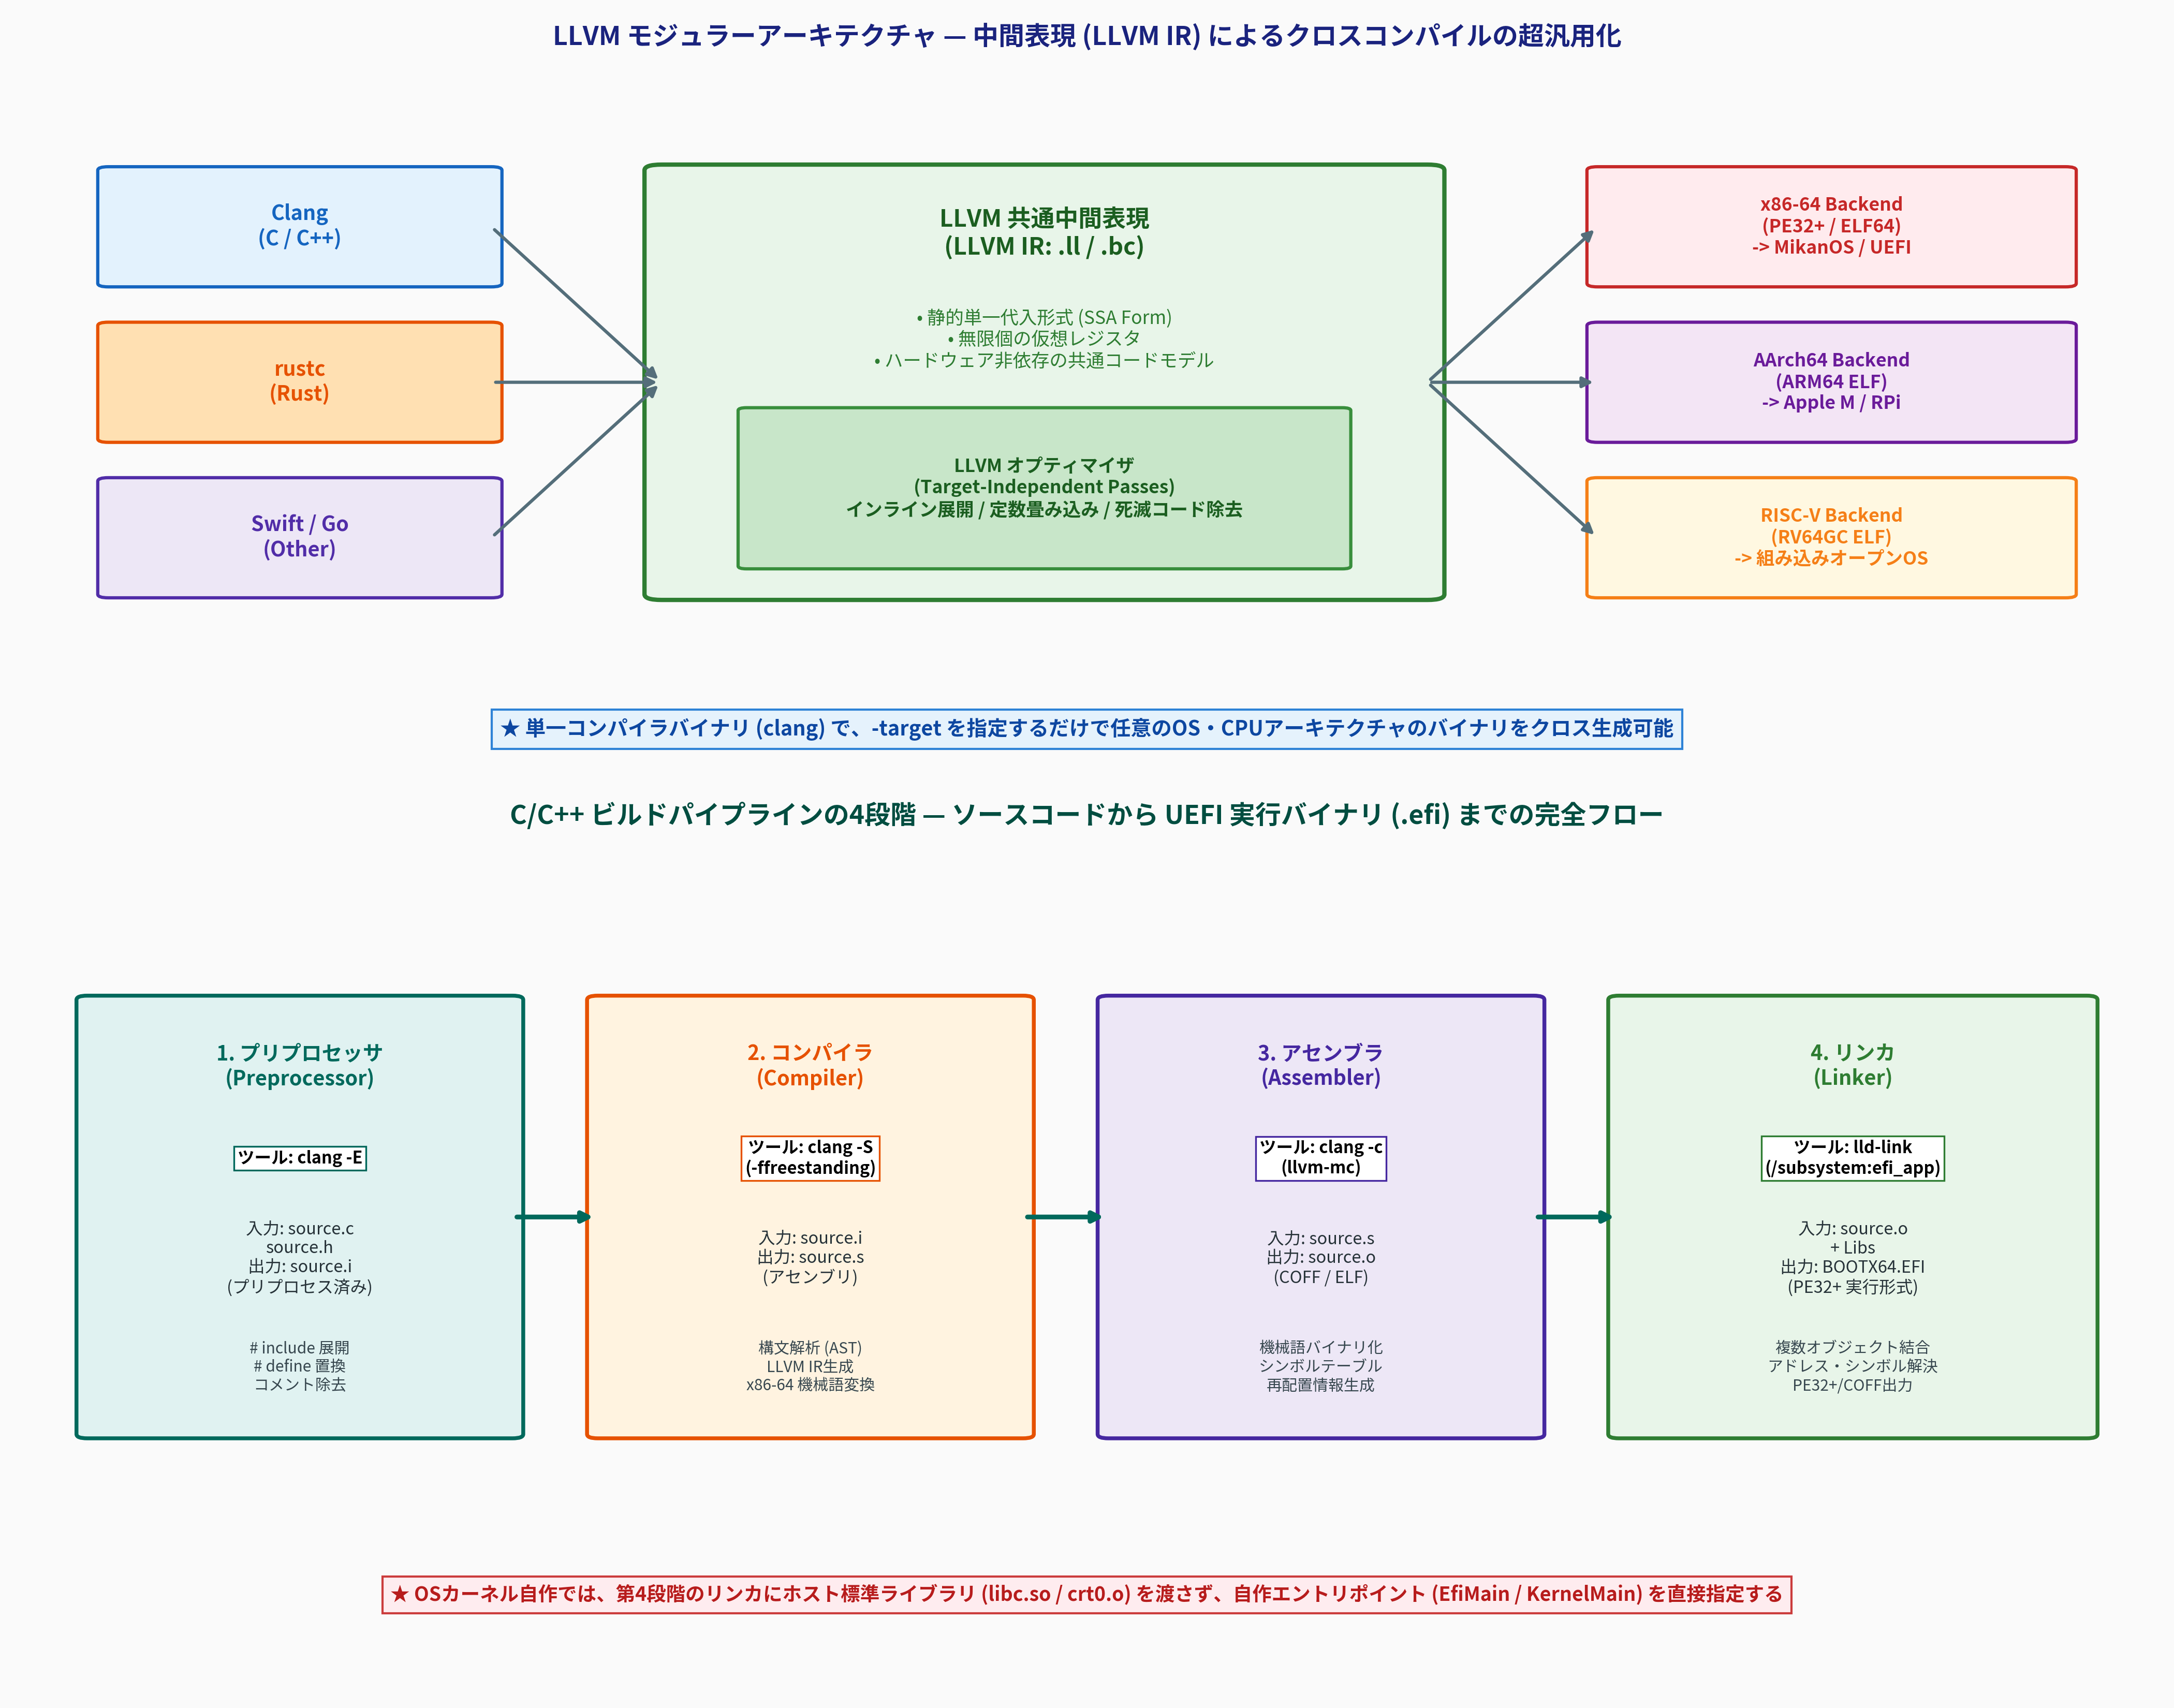

In [2]:
# 高解像度アーキテクチャ図版: LLVM ツールチェーンと 4段階ビルドパイプライン
from common import plot_llvm_toolchain_and_build_pipeline
from IPython.display import Image, display

fig15_path = "result/fig1_15_llvm_toolchain_and_build_pipeline.png"
plot_llvm_toolchain_and_build_pipeline(fig15_path)
display(Image(fig15_path))


## 2. ホスト環境 vs フリースタンディング環境 (*Hosted vs Freestanding*)

C言語 / C++ の規格（ISO/IEC 9899 / 14882）では、プログラムの実行環境を以下の **2種類** に明確に分類しています。

| 分類 | ホスト環境 (*Hosted Environment*) | フリースタンディング環境 (*Freestanding Environment*) |
|---|---|---|
| **対象** | Linux / Windows 上の通常アプリ | **OS カーネル、UEFI ブートローダ、組み込み機器** |
| **下位層** | 既存 OS カーネル + C 標準ライブラリ (libc) | **ベアメタル (裸の CPU・ハードウェア・ファームウェア)** |
| **エントリポイント** | `int main(int argc, char *argv[])` | **任意 (`EfiMain`, `KernelMain` 等)** |
| **標準 libc** | 全機能利用可能 (`printf`, `malloc`, `exit`, `fopen`) | **一切利用不能 (OS 自作側で実装・提供が必要)** |
| **コンパイラフラグ** | デフォルト (`hosted`) | **`-ffreestanding` (必須指定)** |

### なぜ `printf()` や `malloc()` は使えないのか？
一般のプログラミングでは、画面に文字列を表示するために当たり前のように `printf("Hello, World\n");` を呼び出します。
しかし、`printf()` の内部動作を追跡すると：
$$\text{printf()} \longrightarrow \text{libc バッファリング} \longrightarrow \text{write() システムコール} \longrightarrow \text{Ring 3/0 遷移} \longrightarrow \text{TTY / ディスプレイドライバ}$$
という膨大な OS サービスに依存しています。

自作 OS の起動時点では：
1. **システムコールを処理するカーネルが存在しない**（私たちがこれから作る）。
2. **ヒープ領域を管理するメモリアロケータ（`malloc` の土台）が存在しない**（第8章・第9章で実装する）。
3. **文字をフォントとして画面ピクセルに展開するレンダラが存在しない**（第5章で実装する）。

したがって、OS カーネルの世界ではホスト環境の libc は使用禁止であり、コンパイラに対して **`-ffreestanding`** を指定して「ホスト環境の前提をすべて遮断せよ」と指示しなければなりません。

### フリースタンディング環境で許可される「最小限の標準ヘッダ」
C言語規格において、フリースタンディング環境でもコンパイラ自身が提供することが義務付けられているヘッダは、以下の **言語仕様・アーキテクチャ依存の型・マクロ定義のみ** です：
- `<stdint.h>`: 固定幅整数型（`uint8_t`, `uint32_t`, `uint64_t` 等）
- `<stddef.h>`: サイズ型（`size_t`, `ptrdiff_t`）および `NULL` マクロ
- `<stdarg.h>`: 可変長引数マクロ（`va_list`, `va_start`, `va_arg`, `va_end`）
- `<stdbool.h>`: 真偽値型（`bool`, `true`, `false`）
- `<limits.h>` / `<float.h>`: 整数のビット幅や浮動小数点限界値
- `<stdalign.h>` / `<stdnoreturn.h>`: アライメント指定や終了関数属性

※ `<stdio.h>`, `<stdlib.h>`, `<string.h>`, `<math.h>`, `<unistd.h>` などのOS依存ヘッダを `#include` すると、コンパイルエラーまたは未解決シンボルエラーとなります。


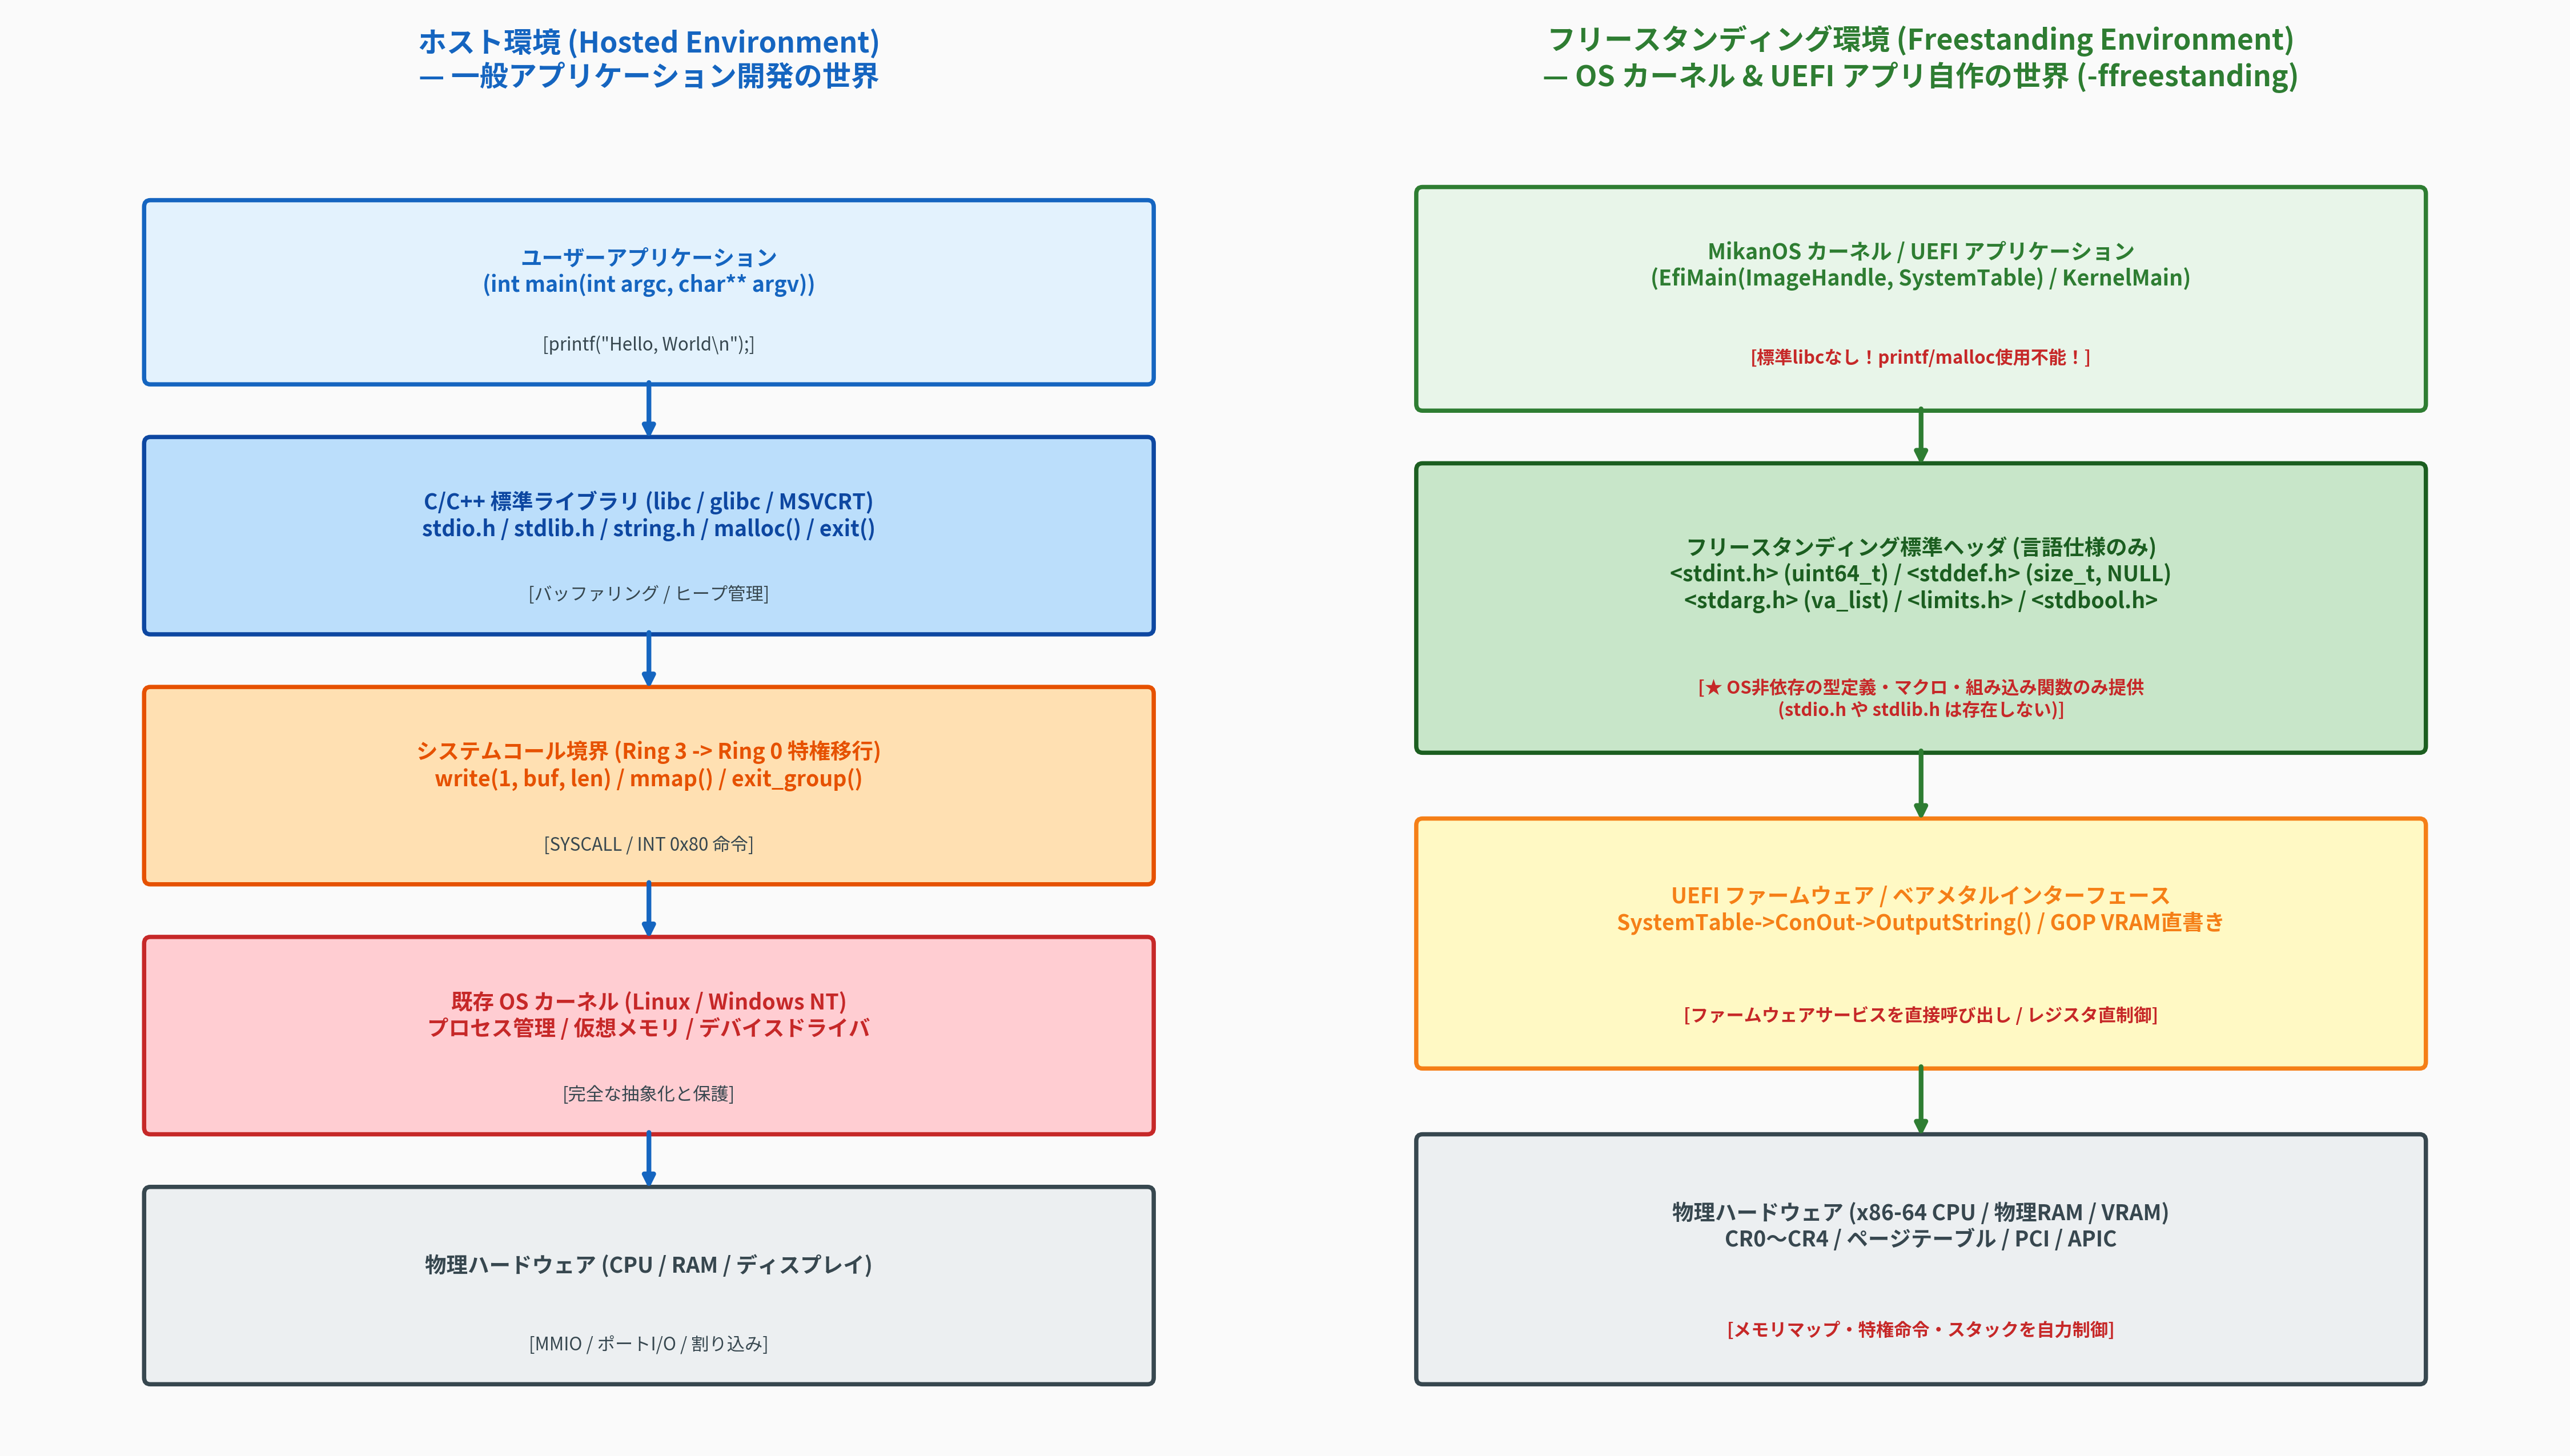

In [3]:
# 高解像度アーキテクチャ図版: ホスト環境 vs フリースタンディング環境の完全比較図
from common import plot_freestanding_vs_hosted_environment
from IPython.display import Image, display

fig16_path = "result/fig1_16_freestanding_vs_hosted_environment.png"
plot_freestanding_vs_hosted_environment(fig16_path)
display(Image(fig16_path))


## 3. ネイティブコンパイル vs クロスコンパイル (*Cross Compilation*) とターゲットトリプル

開発者がコードを書き、コンパイルを行う PC を **ホストマシン (Host Machine)**、生成されたバイナリが実際に起動・実行される PC を **ターゲットマシン (Target Machine)** と呼びます。

- **ネイティブコンパイル (*Native Compilation*)**: ホスト環境とターゲット環境が同一（例: Ubuntu x86_64 上で Ubuntu 用 ELF バイナリをビルド）。
- **クロスコンパイル (*Cross Compilation*)**: ホスト環境とターゲット環境が異なる（例: Ubuntu x86_64 上で UEFI 用 PE32+ バイナリや ARM64 用バイナリをビルド）。

MikanOS のブートローダ開発では、**Linux (Ubuntu / WSL) 上でビルドし、UEFI ファームウェア（Windows 互換の PE32+ / COFF 形式）で動作するバイナリを生成する** ため、完全なクロスコンパイル環境が必要となります。

### ターゲットトリプル (*Target Triple*) の数理・構文構造
LLVM / Clang や GCC では、ターゲット環境を以下の 4 つの要素からなるハイフン区切りの文字列（**ターゲットトリプル**）で一意に指定します：

$$\text{Target Triple} = \text{\textbf{arch}}-\text{\textbf{vendor}}-\text{\textbf{operating\_system}}-\text{\textbf{environment/ABI}}$$

| フィールド | 意味 | MikanOS UEFI アプリ | Linux ホスト環境 | MikanOS カーネル本体 |
|---|---|:---:|:---:|:---:|
| **`arch`** | CPU アーキテクチャ | `x86_64` (64bit x86) | `x86_64` | `x86_64` |
| **`vendor`** | ハードウェア供給元 | `pc` / `unknown` | `unknown` | `unknown` |
| **`os`** | 対象オペレーティングシステム | `win32` / `windows` | `linux` | `elf` / `none` |
| **`env/ABI`** | 実行バイナリ形式 / ABI | `coff` (PE/COFF) | `gnu` (glibc) | `none` (ベアメタル) |
| **完全表記** | `-target` 指定文字列 | **`x86_64-pc-win32-coff`** | `x86_64-unknown-linux-gnu` | `x86_64-elf` |

> [!IMPORTANT]
> **なぜ UEFI アプリなのに `win32` や `windows` なのか？**
> 第1章 1.1節で学んだ通り、UEFI 仕様は Intel と Microsoft が主導して策定された歴史的経緯から、実行バイナリ形式に Windows 標準の **PE32+ (Portable Executable 64-bit)** を採用しています。
> そのため、Clang で UEFI アプリケーションをビルドする際は、`-target x86_64-pc-win32-coff` を指定することで、Linux 上であっても一発で PE32+ / COFF オブジェクトファイルを出力できるのです。


In [4]:
# Python シミュレータによるターゲットトリプル解析とクロスコンパイル適合判定
from common import TargetTriple

triples = [
    "x86_64-unknown-linux-gnu",
    "x86_64-pc-win32-coff",
    "x86_64-elf",
    "aarch64-unknown-none-elf",
    "riscv64-unknown-elf",
]

host = TargetTriple.parse("x86_64-unknown-linux-gnu")
print(f"【ホスト環境】: {host.canonical_string}\n" + "=" * 75)

for t_str in triples:
    t = TargetTriple.parse(t_str)
    is_cross = t.is_cross_compile(host)
    uefi_ok = t.is_uefi_compatible()
    obj_fmt = t.object_format()
    exe_fmt = t.executable_format()
    print(f"Target: {t.canonical_string:<26} | クロス: {'YES' if is_cross else 'NO ':<3} | UEFI適合: {'[OK]' if uefi_ok else ' [--]'} | オブジェクト: {obj_fmt:<6} | 実行形式: {exe_fmt}")


【ホスト環境】: x86_64-unknown-linux-gnu
Target: x86_64-unknown-linux-gnu   | クロス: NO  | UEFI適合:  [--] | オブジェクト: ELF    | 実行形式: ELF64
Target: x86_64-pc-win32-coff       | クロス: YES | UEFI適合: [OK] | オブジェクト: COFF   | 実行形式: PE32+
Target: x86_64-unknown-elf         | クロス: YES | UEFI適合:  [--] | オブジェクト: ELF    | 実行形式: ELF64
Target: aarch64-unknown-none-elf   | クロス: YES | UEFI適合:  [--] | オブジェクト: ELF    | 実行形式: ELF64
Target: riscv64-unknown-elf        | クロス: YES | UEFI適合:  [--] | オブジェクト: ELF    | 実行形式: ELF64


## 4. ビルドパイプラインの4段階と OS 自作の4大必須フラグ

C/C++ のソースコードが機械語実行バイナリになるまでには、以下の **4つの独立した処理段階 (Stages)** を経ます。

```text
 [ 1. プリプロセッサ ] (clang -E)   : #include ヘッダ展開、#define マクロ置換、#ifdef 評価
         ↓ (ソース.i / .ii)
 [ 2. コンパイラ ]     (clang -S)   : 構文解析 (AST) → LLVM IR 最適化 → x86-64 アセンブリ出力
         ↓ (アセンブリ.s)
 [ 3. アセンブラ ]     (clang -c)   : アセンブリ命令を機械語オペコードへ変換、COFF/ELF リロケータブルオブジェクト生成
         ↓ (オブジェクト.o)
 [ 4. リンカ ]         (lld-link)   : 複数オブジェクト結合、外部シンボルアドレス解決、PE32+ 実行ファイル完成
```

### OS 自作を成功させる「4大必須コンパイラフラグ」

OS 自作において、通常のアプリ用フラグのままコンパイルすると、**ブート直後に不可解なフリーズや再起動ループに陥る罠** がいくつも存在します。

#### ① `-ffreestanding` (フリースタンディング環境の強制)
- **目的**: ホスト OS の libc（`glibc` や `msvcrt`）への暗黙の依存を遮断し、標準ヘッダを最小限のものに限定します。
- **落とし穴**: これを指定しないと、コンパイラが `main()` のシグネチャをチェックしたり、未定義のスタートアップコード（`crt0.o`）をリンクしようとしてエラーになります。

#### ② `-mno-red-zone` (レッドゾーンの無効化)
- **目的**: x86-64 System V AMD64 ABI では、関数呼び出し時のスタックポインタ（`RSP`）の下部 **128バイト** が「レッドゾーン (Red Zone)」として予約され、関数は `RSP` をデクリメントせずにこの128バイトを一時変数領域として自由に使ってよい規約になっています。
- **落とし穴**: しかし、**OSカーネルの割り込み（第7章）や UEFI ファームウェアサービス呼び出し** が発生した瞬間、CPU やファームウェアは現在の `RSP` の直下に割り込みフレームやレジスタをプッシュします。その結果、**コンパイラがレッドゾーンに保持していた変数値が一瞬で破壊される** という壊滅的バグを引き起こします。そのため、カーネルやブートローダでは必ず `-mno-red-zone` でレッドゾーンを無効化しなければなりません。

#### ③ `-fno-stack-protector` (スタック保護カナリアの無効化)
- **目的**: GCC や Clang はデフォルトでバッファオーバーフロー攻撃を防ぐため、関数のプロローグでスタックに乱数（カナリア値）を埋め込み、エピローグで検証するコードを自動生成します。
- **落とし穴**: カナリア値の不一致を検知した際に呼び出される関数 `__stack_chk_fail` や乱数シード `__stack_chk_guard` は、ホスト OS の libc が提供するシンボルです。OS 自作環境ではこの関数が存在しないため、**リンク時に未解決シンボルエラーでビルドが失敗** します。

#### ④ `-fshort-wchar` (16ビット Unicode CHAR16 への適合)
- **目的**: UEFI の文字列型 `CHAR16` は **16ビット幅 (UCS-2 / UTF-16LE)** です。しかし、Linux 環境の GCC/Clang におけるデフォルトの `wchar_t` は **32ビット (UTF-32)** です。
- **落とし穴**: これを指定しないと、文字列リテラル `L"Hello"` を UEFI の `OutputString` API に渡した際に文字化けやメモリ不正アクセスが発生します。`-fshort-wchar` を指定することで、`wchar_t` を 16ビット幅に強制します。


In [5]:
# Python シミュレータによるビルドパイプライン追跡と必須コンパイラフラグ監査
from common import CompilerToolchainPipeline

# 1. ビルドパイプライン4段階のトレース
stages = CompilerToolchainPipeline.trace_stages("hello.c", "x86_64-pc-win32-coff")
print("【C言語ソースコードから UEFI 実行バイナリ (.efi) までの4段階変換】\n" + "=" * 75)
for s in stages:
    print(f"段階: {s['stage']}")
    print(f"  ツール: {s['tool']:<20} | 入力 -> 出力: {s['input']} -> {s['output']}")
    print(f"  概要  : {s['description']}\n")

# 2. コンパイラフラグの安全性監査シミュレーション
print("【コンパイラフラグ安全性監査シミュレーション】\n" + "=" * 75)
test_cases = [
    ("完全安全フラグセット (MikanOS推奨)", ["-ffreestanding", "-mno-red-zone", "-fno-stack-protector", "-fshort-wchar", "-O2", "-Wall"]),
    ("一般的なLinuxアプリ用フラグ (OS開発危険)", ["-O2", "-Wall", "-g"]),
    ("Red Zone 未無効化セット (割り込みスタック破壊の罠)", ["-ffreestanding", "-fno-stack-protector", "-fshort-wchar"]),
]

for title, flags in test_cases:
    res = CompilerToolchainPipeline.validate_compiler_flags(flags)
    status = "[SAFE] 全て合格" if res['is_safe_for_os_dev'] else "[DANGER] 欠落フラグあり"
    print(f"{title}: スコア {res['score_percent']:.0f}% -> {status}")
    if res['missing_flags']:
        for m_flag, m_desc in res['missing_flags'].items():
            print(f"   ! 警告: 必須フラグ '{m_flag}' が欠落しています ({m_desc})")
    print()


【C言語ソースコードから UEFI 実行バイナリ (.efi) までの4段階変換】
段階: 1. プリプロセッサ (Preprocessing)
  ツール: clang -E             | 入力 -> 出力: hello.c / hello.cpp -> hello.i / hello.ii
  概要  : #include ヘッダ展開、#define マクロ置換、条件付きコンパイル (#ifdef) の評価

段階: 2. コンパイラ (Compilation)
  ツール: clang -S (or -emit-llvm) | 入力 -> 出力: hello.i -> hello.s (Assembly) / hello.ll (LLVM IR)
  概要  : 構文解析、中間表現 (LLVM IR) 最適化、ターゲットアーキテクチャ依存のアセンブリ言語生成

段階: 3. アセンブラ (Assembler)
  ツール: clang -c (llvm-mc)   | 入力 -> 出力: hello.s -> hello.o (COFF Relocatable Object)
  概要  : アセンブリから機械語バイナリへの変換、未解決外部シンボルと再配置情報の生成 (COFF形式)

段階: 4. リンカ (Linker)
  ツール: lld-link / ld.lld    | 入力 -> 出力: hello.o + Libs -> hello.efi (PE32+)
  概要  : 複数オブジェクトと静的ライブラリの結合、シンボルアドレス解決、最終実行可能バイナリ (PE32+) の出力

【コンパイラフラグ安全性監査シミュレーション】
完全安全フラグセット (MikanOS推奨): スコア 100% -> [SAFE] 全て合格

一般的なLinuxアプリ用フラグ (OS開発危険): スコア 0% -> [DANGER] 欠落フラグあり
   ! 警告: 必須フラグ '-ffreestanding' が欠落しています (ホスト libc への依存を遮断し、フリースタンディング環境としてコンパイル)
   ! 警告: 必須フラグ '-mno-red-zone' が欠落しています (割り込みやファームウェア呼び出し時のスタック128バイトR

## 5. C++20 スタンドアロン検証ツールによるバイナリ構造検証

本リポジトリでは、ターゲットトリプル構文解析、フリースタンディングヘッダ適合性検査、およびコンパイラオプションの安全性を C++20 で厳密に検証するスタンドアロンツール **`src/ch01/toolchain_inspector.cpp`** を提供しています。

以下のセルを実行し、CMake ターゲット `ch01_toolchain_inspector` をビルド・実行して検証結果を確認しましょう。


In [6]:
# C++20 スタンドアロン検証ツールの実行 (CMake ターゲット: ch01_toolchain_inspector)
!cmake --build ../build --target ch01_toolchain_inspector
!../build/bin/ch01_toolchain_inspector


[100%] Built target ch01_toolchain_inspector


  MikanOS Section 1.8: OSを作る道具 (Compiler Toolchain Inspector)

[1] Target Triple Analysis:
  - Host Triple:   x86_64-unknown-linux-gnu (Object: ELF, Executable: ELF64)
  - UEFI Target:   x86_64-pc-win32-coff (Object: COFF, Executable: PE32+)
  - Kernel Target: x86_64-unknown-elf (Object: ELF, Executable: ELF64)
  - Cross-compilation (Host -> UEFI): YES (クロスコンパイル必須)
  - UEFI Compatibility: YES (PE/COFF 生成可能)

[2] Freestanding Environment Header Compliance:
  - Allowed (Freestanding): <stdint.h> <stddef.h> <stdarg.h> 
  - Forbidden (Hosted Only): <stdio.h> <string.h> 
  - Result: VIOLATION (ホストlibc依存あり！OSカーネルでは利用不可)

[3] Compiler Flags Safety Audit (MikanOS UEFI Toolchain):
  - Safety Score: 100.0%
  - Passed Essential Flags: -ffreestanding -mno-red-zone -fno-stack-protector -fshort-wchar 
  - Status: SAFE (OS自作の全必須フラグ完備)

[+] All self-verification assertions passed successfully!


## 6. 理解度セルフチェック演習（即時自己採点）

本節で学んだターゲットトリプル、フリースタンディング環境、およびビルドパイプラインに関する理解を定着させるための演習問題です。
以下のセル内の変数 `ans_q1` 〜 `ans_q5` に適切な値を入力し、セルを実行して即時自己採点を行ってください。

### 問題一覧
1. **Q1 (ターゲットトリプル)**: MikanOS の UEFI アプリケーション（PE/COFF形式）を出力するために Clang の `-target` オプションに指定するターゲットトリプル文字列は何か？
2. **Q2 (フリースタンディング環境)**: ISO C規格のフリースタンディング環境において、標準で利用が**禁止（ホスト依存のため利用不可）**されているヘッダは次のうちどれか？ (`"stdint.h"`, `"stdio.h"`, `"stddef.h"`, `"stdarg.h"`)
3. **Q3 (Red Zone の罠)**: x86-64 System V AMD64 ABI において、スタックポインタ `RSP` の直下に予約され、割り込み発生時に破壊されるリスクがある領域のサイズは何バイトか？
4. **Q4 (UEFI 文字列幅)**: UEFI の `CHAR16` 型に文字列リテラルを適合させるため、`wchar_t` のサイズを 16ビットに強制するコンパイラフラグは何か？
5. **Q5 (ビルド段階)**: C言語のプリプロセス済みソースコード（`.i`）を入力として受け取り、構文解析とLLVM IR最適化を経てアセンブリ言語（`.s`）を出力するツールの段階名は何か？ (`"preprocessor"`, `"compiler"`, `"assembler"`, `"linker"`)


In [7]:
# === 理解度セルフチェック演習（解答入力セル） ===
# ※下記の変数にご自身の解答を入力してセルを実行してください。

ans_q1_target_triple = "x86_64-pc-win32-coff" # Q1: UEFI用PE/COFF出力ターゲットトリプル
ans_q2_forbidden_header = "stdio.h"          # Q2: フリースタンディングで利用不可のヘッダ
ans_q3_red_zone_bytes = 128                  # Q3: Red Zone のバイト数 (int)
ans_q4_wchar_flag = "-fshort-wchar"          # Q4: 16-bit wchar_t 指定フラグ
ans_q5_stage_name = "compiler"               # Q5: .i -> .s を生成する処理段階

# === 自動採点ロジック ===
score = 0
total = 5

# Q1 判定
if ans_q1_target_triple.strip() in ["x86_64-pc-win32-coff", "x86_64-unknown-windows"]:
    score += 1
    print("Q1: 正解! (x86_64-pc-win32-coff により UEFI 向け PE32+/COFF バイナリを出力)")
else:
    print(f"Q1: 不正解 (入力: {ans_q1_target_triple})")

# Q2 判定
if ans_q2_forbidden_header.strip("<> ") == "stdio.h":
    score += 1
    print("Q2: 正解! (<stdio.h> は OS のシステムコール write() に依存するためフリースタンディングでは利用不能)")
else:
    print(f"Q2: 不正解 (入力: {ans_q2_forbidden_header})")

# Q3 判定
if ans_q3_red_zone_bytes == 128:
    score += 1
    print("Q3: 正解! (128バイトの Red Zone は割り込みやファームウェア呼び出し時に破壊されるため -mno-red-zone が必須)")
else:
    print(f"Q3: 不正解 (入力: {ans_q3_red_zone_bytes})")

# Q4 判定
if ans_q4_wchar_flag.strip() == "-fshort-wchar":
    score += 1
    print("Q4: 正解! (-fshort-wchar により wchar_t を UEFI CHAR16 規格の 16ビットに整合)")
else:
    print(f"Q4: 不正解 (入力: {ans_q4_wchar_flag})")

# Q5 判定
if ans_q5_stage_name.strip().lower() == "compiler":
    score += 1
    print("Q5: 正解! (コンパイラ本体が AST・LLVM IR を経てアセンブリ .s を生成)")
else:
    print(f"Q5: 不正解 (入力: {ans_q5_stage_name})")

print("-" * 50)
print(f"最終得点: {score} / {total} 点 ({score / total * 100:.0f}%)")
assert score == total, f"{total - score} 問の間違いがあります。解説を読み直して再挑戦してください。"
print("🎉 満点です！OS自作のツールチェーンとフリースタンディング環境の理論を完全に習得しました！")


Q1: 正解! (x86_64-pc-win32-coff により UEFI 向け PE32+/COFF バイナリを出力)
Q2: 正解! (<stdio.h> は OS のシステムコール write() に依存するためフリースタンディングでは利用不能)
Q3: 正解! (128バイトの Red Zone は割り込みやファームウェア呼び出し時に破壊されるため -mno-red-zone が必須)
Q4: 正解! (-fshort-wchar により wchar_t を UEFI CHAR16 規格の 16ビットに整合)
Q5: 正解! (コンパイラ本体が AST・LLVM IR を経てアセンブリ .s を生成)
--------------------------------------------------
最終得点: 5 / 5 点 (100%)
🎉 満点です！OS自作のツールチェーンとフリースタンディング環境の理論を完全に習得しました！


## 7. 本節のまとめと次節（1.9 節「C言語でハローワールド」）への展望

本節では、OS 自作という極限の環境における開発道具のアーキテクチャを体系的に学びました。

### 本節の重要ポイント総括
1. **C言語 / C++ の必然性**: 物理アドレス直アクセス（ポインタ）、ゼロランタイム自立実行、インラインアセンブラ特権命令を両立できる唯一の現実解。
2. **フリースタンディング環境 (`-ffreestanding`)**: 既存 OS の libc 依存を完全に遮断し、`<stdint.h>` や `<stddef.h>` などの最小限のヘッダのみでベアメタル動作を実現。
3. **クロスコンパイルとターゲットトリプル**: Linux ホスト環境から `-target x86_64-pc-win32-coff` を指定することで、UEFI 規格に合致した PE32+ / COFF バイナリを出力。
4. **LLVM / Clang のモジュラー設計**: Clang Frontend $\to$ LLVM IR $\to$ CodeGen Backend $\to$ LLD Linker による自由自在なクロスビルドパイプライン。
5. **4大必須コンパイラフラグ**: `-ffreestanding`, `-mno-red-zone`, `-fno-stack-protector`, `-fshort-wchar` を正しく指定しなければ、スタック破壊や未定義参照で OS は即座に死ぬ。

---

### 🚀 次節への展望：1.9 C言語でハローワールド

道具立ての理論が完璧に揃った今、次節 **1.9 節「C言語でハローワールド」** では、いよいよ本物の C言語ソースコード（`hello.c`）を記述します！

- `EfiMain(EFI_HANDLE ImageHandle, EFI_SYSTEM_TABLE *SystemTable)` のシグネチャ解剖
- `SystemTable->ConOut->OutputString` による構造体ポインタ経由の UEFI サービス呼び出し
- Clang と LLD (`lld-link`) による実際のクロスコンパイルと実行バイナリ生成
- 付随コラム 1.1「PE と COFF と ELF」におけるバイナリフォーマットの徹底比較

バイナリエディタで1バイトずつ打ち込んでいた世界から、現代的なコンパイラによる高水準な OS 自作の世界へ、堂々と足を踏み入れましょう！
